# 02 — Treasury curve and the Hull–White rate model

**Curve.** The trade-date CMT par yields (1M–30Y) are bootstrapped into a continuously compounded zero
curve $P^M(0,T)$:
- bills are simple coupon-equivalent yields;
- coupon tenors are semiannual par bonds;
- zero rates are linear between knots;
- every input is repriced exactly.

**Model.** One-factor Hull–White: $r(t)=x(t)+\varphi(t)$ with $dx=-\kappa x\,dt+\sigma\,dW$ and $x(0)=0$.
$\varphi$ makes the model reproduce $P^M(0,T)$ exactly. Pathwise discount factors and future bond prices are:

$$D(0,T)=P^M(0,T)\,e^{-V(T)/2-Y(T)},\qquad
P(t,T)=\frac{P^M(0,T)}{P^M(0,t)}\exp\!\Big(\tfrac12[V(T-t)-V(T)+V(t)]-B(T-t)\,x(t)\Big)$$

Here $B(\tau)=(1-e^{-\kappa\tau})/\kappa$, $Y(T)=\int_0^T x\,ds$ and $V(\tau)=\operatorname{Var}\,Y(\tau)$.
$(x,Y)$ is drawn exactly as a bivariate Gaussian on any grid.

**Calibration.** In this model the normal vol of the $\tau$-year zero yield is $\sigma B(\tau)/\tau$.
$\kappa$ and $\sigma$ are fitted by least squares to the realised vol of daily zero-yield changes at 2–30Y
over the two years to the trade date. The decay of vol along the curve identifies $\kappa$ as it enters
bond pricing. That is the quantity the old time-series AR(1) fit to the 1Y rate could not recover.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import plot_style as ps

ps.apply()
pd.set_option("display.width", 140)
CUSIP = "3140QVLM4"

In [2]:
from curve import bootstrap_par_curve
from hull_white import HullWhite, calibrate_hull_white, zero_yield_history
from run_security_analytics import VOL_WINDOW_YEARS, load_inputs

inputs = load_inputs(CUSIP)
trade, cmt = inputs["trade_date"], inputs["cmt"]
curve = bootstrap_par_curve(cmt.columns.to_numpy(float), cmt.loc[trade].to_numpy(float))
table = pd.DataFrame({
    "CMT par %": curve.par_yields * 100,
    "zero (cont.) %": curve.knot_zeros * 100,
    "repricing error bp": [(curve.par_yield(t) - y) * 1e4 for t, y in zip(curve.par_tenors, curve.par_yields)],
}, index=pd.Index(curve.par_tenors.round(3), name="tenor (y)"))
print(f"Curve date {trade.date()}")
table.round(4)

Curve date 2026-10-09


,CMT par %,zero (cont.) %,repricing error bp
tenor (y),,,
0.083,4.13,4.1229,-0.0
0.250,4.25,4.2276,-0.0
0.500,4.32,4.2740,0.0
1.000,4.47,4.4224,0.0
2.000,4.80,4.7530,0.0
3.000,4.89,4.8424,-0.0
5.000,5.02,4.9759,-0.0
7.000,5.13,5.0941,0.0
10.000,5.24,5.2169,0.0


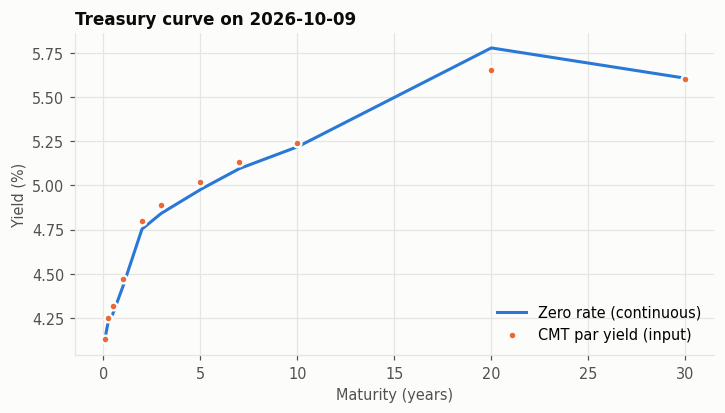

In [3]:
t = np.linspace(0.05, 30, 400)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(t, curve.zero_rate(t) * 100, color=ps.SERIES[0], label="Zero rate (continuous)")
ax.scatter(curve.par_tenors, curve.par_yields * 100, color=ps.SERIES[1], zorder=3, s=26,
           edgecolor=ps.SURFACE, linewidth=1.5, label="CMT par yield (input)")
ax.set(xlabel="Maturity (years)", ylabel="Yield (%)", title=f"Treasury curve on {trade.date()}")
ax.legend(loc="lower right")
_ = ps.save(fig, "02_treasury_curve")

,estimate,CI 2.5%,CI 97.5%
kappa (1/yr),0.0064,0.0000,0.0143
sigma (bp/yr),81.5417,73.8613,89.7771


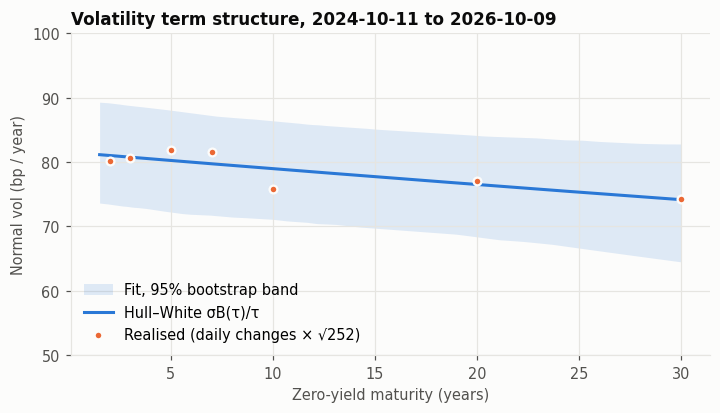

In [4]:
window = cmt.loc[cmt.index > trade - pd.DateOffset(years=VOL_WINDOW_YEARS)]
cal = calibrate_hull_white(zero_yield_history(window), n_boot=500, seed=42)
hw = HullWhite(cal["kappa"], cal["sigma"])
tenors = np.array(cal["tenors"])
tau = np.linspace(1.5, 30, 200)
fits = np.array([HullWhite(k, s).zero_yield_vol(tau) for k, s in cal["bootstrap"]])
lo, hi = np.percentile(fits, [2.5, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.fill_between(tau, lo * 1e4, hi * 1e4, color=ps.SERIES[0], alpha=0.14, linewidth=0, label="Fit, 95% bootstrap band")
ax.plot(tau, hw.zero_yield_vol(tau) * 1e4, color=ps.SERIES[0], label="Hull–White σB(τ)/τ")
ax.scatter(tenors, np.array(cal["realized_vol"]) * 1e4, color=ps.SERIES[1], zorder=3, s=26,
           edgecolor=ps.SURFACE, linewidth=1.5, label="Realised (daily changes × √252)")
ax.set(xlabel="Zero-yield maturity (years)", ylabel="Normal vol (bp / year)",
       title=f"Volatility term structure, {cal['window_start']} to {cal['window_end']}", ylim=(50, 100))
ax.legend(loc="lower left")
_ = ps.save(fig, "02_vol_term_structure")
pd.DataFrame({
    "estimate": [cal["kappa"], cal["sigma"] * 1e4],
    "CI 2.5%": [cal["kappa_ci95"][0], cal["sigma_ci95"][0] * 1e4],
    "CI 97.5%": [cal["kappa_ci95"][1], cal["sigma_ci95"][1] * 1e4],
}, index=["kappa (1/yr)", "sigma (bp/yr)"]).round(4)

$\kappa$ is close to zero. Realised vol is almost flat from 2Y to 30Y, so yield shocks barely decay along
the curve. The old physical AR(1) fit on 1953–2026 GS1 data gave $\kappa=0.090$. That number described how
fast the level of rates has mean-reverted over seven decades, not how bond prices load on today's shocks.

**Unbiasedness check.** With exact simulation, the Monte Carlo mean of the pathwise discount factor should
match the curve to within Monte Carlo error at every horizon.

In [5]:
check_t = np.array([0.5, 2.0, 5.0, 10.0, 20.0, 28.0])
x, y_int = hw.simulate_state(check_t, 50_000, seed=1)
disc = hw.discount_factors(curve, check_t, y_int)
se = disc.std(axis=0, ddof=1) / np.sqrt(len(disc))
pd.DataFrame({"curve P(0,T)": curve.discount(check_t), "MC mean": disc.mean(axis=0),
              "z-score": (disc.mean(axis=0) - curve.discount(check_t)) / se},
             index=pd.Index(check_t, name="T (y)")).round(5)

,"curve P(0,T)",MC mean,z-score
T (y),,,
0.5,0.97886,0.97885,-0.25304
2.0,0.90932,0.90935,0.59772
5.0,0.77974,0.78000,1.42825
10.0,0.59351,0.59409,1.48619
20.0,0.31493,0.31545,0.87907
28.0,0.20614,0.20658,0.65468


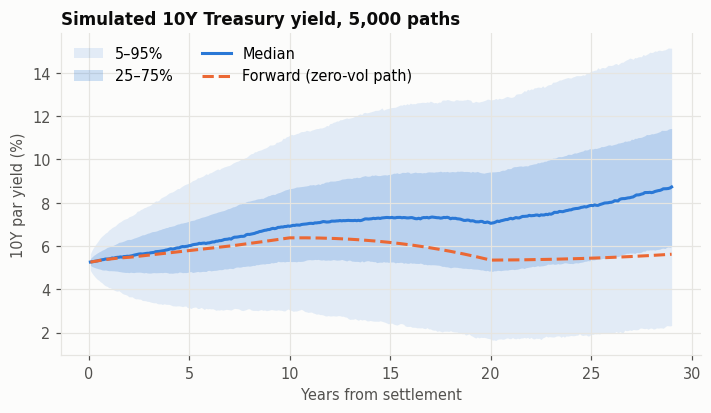

In [6]:
horizon = np.arange(1, 29 * 12 + 1) / 12.0
x, _ = hw.simulate_state(horizon, 5_000, seed=42)
par10 = hw.par_yields(curve, horizon, 10.0, x)
forward10 = HullWhite(hw.kappa, 0.0).par_yields(curve, horizon, 10.0, np.zeros((1, horizon.size)))[0]
q = np.percentile(par10, [5, 25, 50, 75, 95], axis=0) * 100
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.fill_between(horizon, q[0], q[4], color=ps.SERIES[0], alpha=0.12, linewidth=0, label="5–95%")
ax.fill_between(horizon, q[1], q[3], color=ps.SERIES[0], alpha=0.22, linewidth=0, label="25–75%")
ax.plot(horizon, q[2], color=ps.SERIES[0], label="Median")
ax.plot(horizon, forward10 * 100, color=ps.SERIES[1], linestyle="--", label="Forward (zero-vol path)")
ax.set(xlabel="Years from settlement", ylabel="10Y par yield (%)", title="Simulated 10Y Treasury yield, 5,000 paths")
ax.legend(loc="upper left", ncol=2)
_ = ps.save(fig, "02_ten_year_fan")